# Entrenamiento, Evaluación, Selección y Calibración del Modelo FAQ — UPQ

Este notebook implementa el flujo completo de aprendizaje supervisado para el **Chatbot de Preguntas Frecuentes (FAQ) de la Universidad Politécnica de Querétaro (UPQ)**, cubriendo las **Fases 3 y 4** del cronograma oficial:

1. **Carga y exploración del corpus expandido** (`data/corpus_upq.csv`) con 810 registros distribuidos en 15 intenciones oficiales (54 variantes por clase).
2. **Preprocesamiento y normalización de texto** con `limpiar_texto` (`src/preprocess.py`).
3. **Partición estratificada 80/20** (`train_test_split` con `stratify=y` y `random_state=42`).
4. **Vectorización TF-IDF** ajustada **exclusivamente sobre el conjunto de entrenamiento** (`fit_transform` en train, `transform` en test) para prevenir fuga de datos (*data leakage*).
5. **Entrenamiento y evaluación de 3 clasificadores supervisados**:
   - `LogisticRegression`
   - `CalibratedClassifierCV(LinearSVC)`
   - `MultinomialNB`
6. **Validación cruzada estratificada (5-fold con Pipeline)** encapsulando el vectorizador para certificar la reproducibilidad y ausencia de leakage.
7. **Matrices de confusión** y **tabla comparativa final** ordenada por F1-score macro.
8. **Análisis automático de errores**: inspección detallada de muestras mal clasificadas en el conjunto de prueba.
9. **Calibración de fallback (OOD)**: análisis de confianza con preguntas fuera de dominio para determinar el umbral óptimo de rechazo.
10. **Justificación técnica del modelo ganador** y **exportación de artefactos** (`models/modelo.pkl`, `models/vectorizador.pkl`, `reports/metrics.json`).

## 1. Importación de librerías y configuración de rutas

In [1]:
import json
import sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.calibration import CalibratedClassifierCV
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import (
    StratifiedKFold,
    cross_val_score,
    train_test_split,
)
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC

# Configurar directorio raíz del proyecto
BASE_DIR = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
if str(BASE_DIR) not in sys.path:
    sys.path.insert(0, str(BASE_DIR))

from src.preprocess import limpiar_texto

DATA_PATH = BASE_DIR / "data" / "corpus_upq.csv"
MODELS_DIR = BASE_DIR / "models"
REPORTS_DIR = BASE_DIR / "reports"
VECTORIZER_OUTPUT_PATH = MODELS_DIR / "vectorizador.pkl"
MODEL_OUTPUT_PATH = MODELS_DIR / "modelo.pkl"
METRICS_OUTPUT_PATH = REPORTS_DIR / "metrics.json"

MODELS_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

print(f"Directorio base del proyecto: {BASE_DIR}")

Directorio base del proyecto: /home/marco/Documentos/Tareaesp2/Tarea-especial2


## 2. Carga y exploración del corpus (`data/corpus_upq.csv`)

Verificamos la carga de las 810 muestras en las 15 intenciones oficiales y comprobamos el balance perfecto de clases.

In [2]:
if not DATA_PATH.exists():
    raise FileNotFoundError(f"No se encontró el corpus en: {DATA_PATH}")

df = pd.read_csv(DATA_PATH, encoding="utf-8")
columnas_requeridas = {"texto", "intencion", "respuesta_oficial"}
if not columnas_requeridas.issubset(df.columns):
    raise ValueError(f"El CSV debe contener las columnas: {columnas_requeridas}")

df = df.dropna(subset=["texto", "intencion", "respuesta_oficial"]).copy()
print(f"Total de registros cargados: {len(df)}")
print(f"Número de intenciones: {df['intencion'].nunique()}")
print("\nDistribución por intención:")
print(df["intencion"].value_counts().to_string())
df.head()

Total de registros cargados: 810
Número de intenciones: 15

Distribución por intención:
intencion
admisiones                       54
oferta_educativa                 54
costos_pagos                     54
becas                            54
servicios_escolares              54
calendario_horarios              54
estancias_estadias               54
servicio_social                  54
titulacion                       54
idiomas_ingles                   54
ubicacion_transporte             54
actividades_extracurriculares    54
biblioteca_instalaciones         54
plataforma_sistemas              54
contacto_directorio              54


,texto,intencion,respuesta_oficial
0,¿Cuándo abre la convocatoria de admisión para ...,admisiones,El proceso de admisión de la Universidad Polit...
1,¿Cuáles son los requisitos para inscribirme co...,admisiones,El proceso de admisión de la Universidad Polit...
2,¿Cómo puedo sacar mi ficha para el examen de a...,admisiones,El proceso de admisión de la Universidad Polit...
3,¿Qué documentos necesito entregar para el proc...,admisiones,El proceso de admisión de la Universidad Polit...
4,¿Cuándo es la fecha del examen de admisión de ...,admisiones,El proceso de admisión de la Universidad Polit...


## 3. Limpieza y preprocesamiento de texto

Aplicamos la función institucional `limpiar_texto` de `src/preprocess.py` (minúsculas, remoción de acentos/diacríticos NFD, eliminación de caracteres no alfanuméricos y normalización de espacios).

In [3]:
df["texto_limpio"] = df["texto"].astype(str).apply(limpiar_texto)
X = df["texto_limpio"]
y = df["intencion"].astype(str)

print("Ejemplo de preprocesamiento:")
df[["texto", "texto_limpio", "intencion"]].head(8)

Ejemplo de preprocesamiento:


,texto,texto_limpio,intencion
0,¿Cuándo abre la convocatoria de admisión para ...,cuando abre la convocatoria de admision para n...,admisiones
1,¿Cuáles son los requisitos para inscribirme co...,cuales son los requisitos para inscribirme com...,admisiones
2,¿Cómo puedo sacar mi ficha para el examen de a...,como puedo sacar mi ficha para el examen de ad...,admisiones
3,¿Qué documentos necesito entregar para el proc...,que documentos necesito entregar para el proce...,admisiones
4,¿Cuándo es la fecha del examen de admisión de ...,cuando es la fecha del examen de admision de l...,admisiones
5,¿Dónde consulto la convocatoria vigente para a...,donde consulto la convocatoria vigente para as...,admisiones
6,¿Cuál es el proceso paso a paso para entrar a ...,cual es el proceso paso a paso para entrar a e...,admisiones
7,¿Dónde y cuándo se publican los resultados del...,donde y cuando se publican los resultados del ...,admisiones


## 4. División Estratificada 80/20 y Vectorización TF-IDF

Partición estratificada con `train_test_split(stratify=y, random_state=42)`.
El vectorizador `TfidfVectorizer(ngram_range=(1, 2))` se ajusta **únicamente sobre `X_train`** para garantizar cero fuga de datos (*data leakage*).

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42,
)

vectorizador = TfidfVectorizer(ngram_range=(1, 2))
X_train_tfidf = vectorizador.fit_transform(X_train)
X_test_tfidf = vectorizador.transform(X_test)

print(f"Tamaño de entrenamiento: {X_train_tfidf.shape[0]} muestras | Vocabulario TF-IDF: {X_train_tfidf.shape[1]} términos")
print(f"Tamaño de prueba:        {X_test_tfidf.shape[0]} muestras")

Tamaño de entrenamiento: 648 muestras | Vocabulario TF-IDF: 5238 términos
Tamaño de prueba:        162 muestras


## 5. Entrenamiento y Evaluación Comparativa de Modelos

Entrenamos tres clasificadores con soporte para estimación de probabilidades:
1. `LogisticRegression(max_iter=1000, random_state=42)`
2. `CalibratedClassifierCV(LinearSVC(random_state=42), cv=3)`
3. `MultinomialNB()`

Calculamos métricas completas y generamos las matrices de confusión 15×15.

Modelo: logistic_regression
----------------------------------------------------------------------
                               precision    recall  f1-score   support

actividades_extracurriculares       0.88      0.70      0.78        10
                   admisiones       0.70      0.64      0.67        11
                        becas       0.83      0.91      0.87        11
     biblioteca_instalaciones       1.00      0.73      0.84        11
          calendario_horarios       0.69      0.82      0.75        11
          contacto_directorio       0.88      0.64      0.74        11
                 costos_pagos       0.89      0.73      0.80        11
           estancias_estadias       1.00      0.82      0.90        11
               idiomas_ingles       0.85      1.00      0.92        11
             oferta_educativa       0.73      0.80      0.76        10
          plataforma_sistemas       0.77      0.91      0.83        11
              servicio_social       1.00      1.

Modelo: linear_svc_calibrated
----------------------------------------------------------------------
                               precision    recall  f1-score   support

actividades_extracurriculares       0.80      0.80      0.80        10
                   admisiones       0.70      0.64      0.67        11
                        becas       0.91      0.91      0.91        11
     biblioteca_instalaciones       1.00      0.64      0.78        11
          calendario_horarios       0.64      0.82      0.72        11
          contacto_directorio       0.73      0.73      0.73        11
                 costos_pagos       0.89      0.73      0.80        11
           estancias_estadias       1.00      0.82      0.90        11
               idiomas_ingles       0.85      1.00      0.92        11
             oferta_educativa       0.82      0.90      0.86        10
          plataforma_sistemas       0.69      0.82      0.75        11
              servicio_social       1.00      

Modelo: multinomial_nb
----------------------------------------------------------------------
                               precision    recall  f1-score   support

actividades_extracurriculares       1.00      0.70      0.82        10
                   admisiones       0.73      0.73      0.73        11
                        becas       0.83      0.91      0.87        11
     biblioteca_instalaciones       1.00      0.64      0.78        11
          calendario_horarios       0.69      0.82      0.75        11
          contacto_directorio       0.88      0.64      0.74        11
                 costos_pagos       0.89      0.73      0.80        11
           estancias_estadias       1.00      0.82      0.90        11
               idiomas_ingles       0.73      1.00      0.85        11
             oferta_educativa       0.80      0.80      0.80        10
          plataforma_sistemas       0.83      0.91      0.87        11
              servicio_social       0.91      1.00   

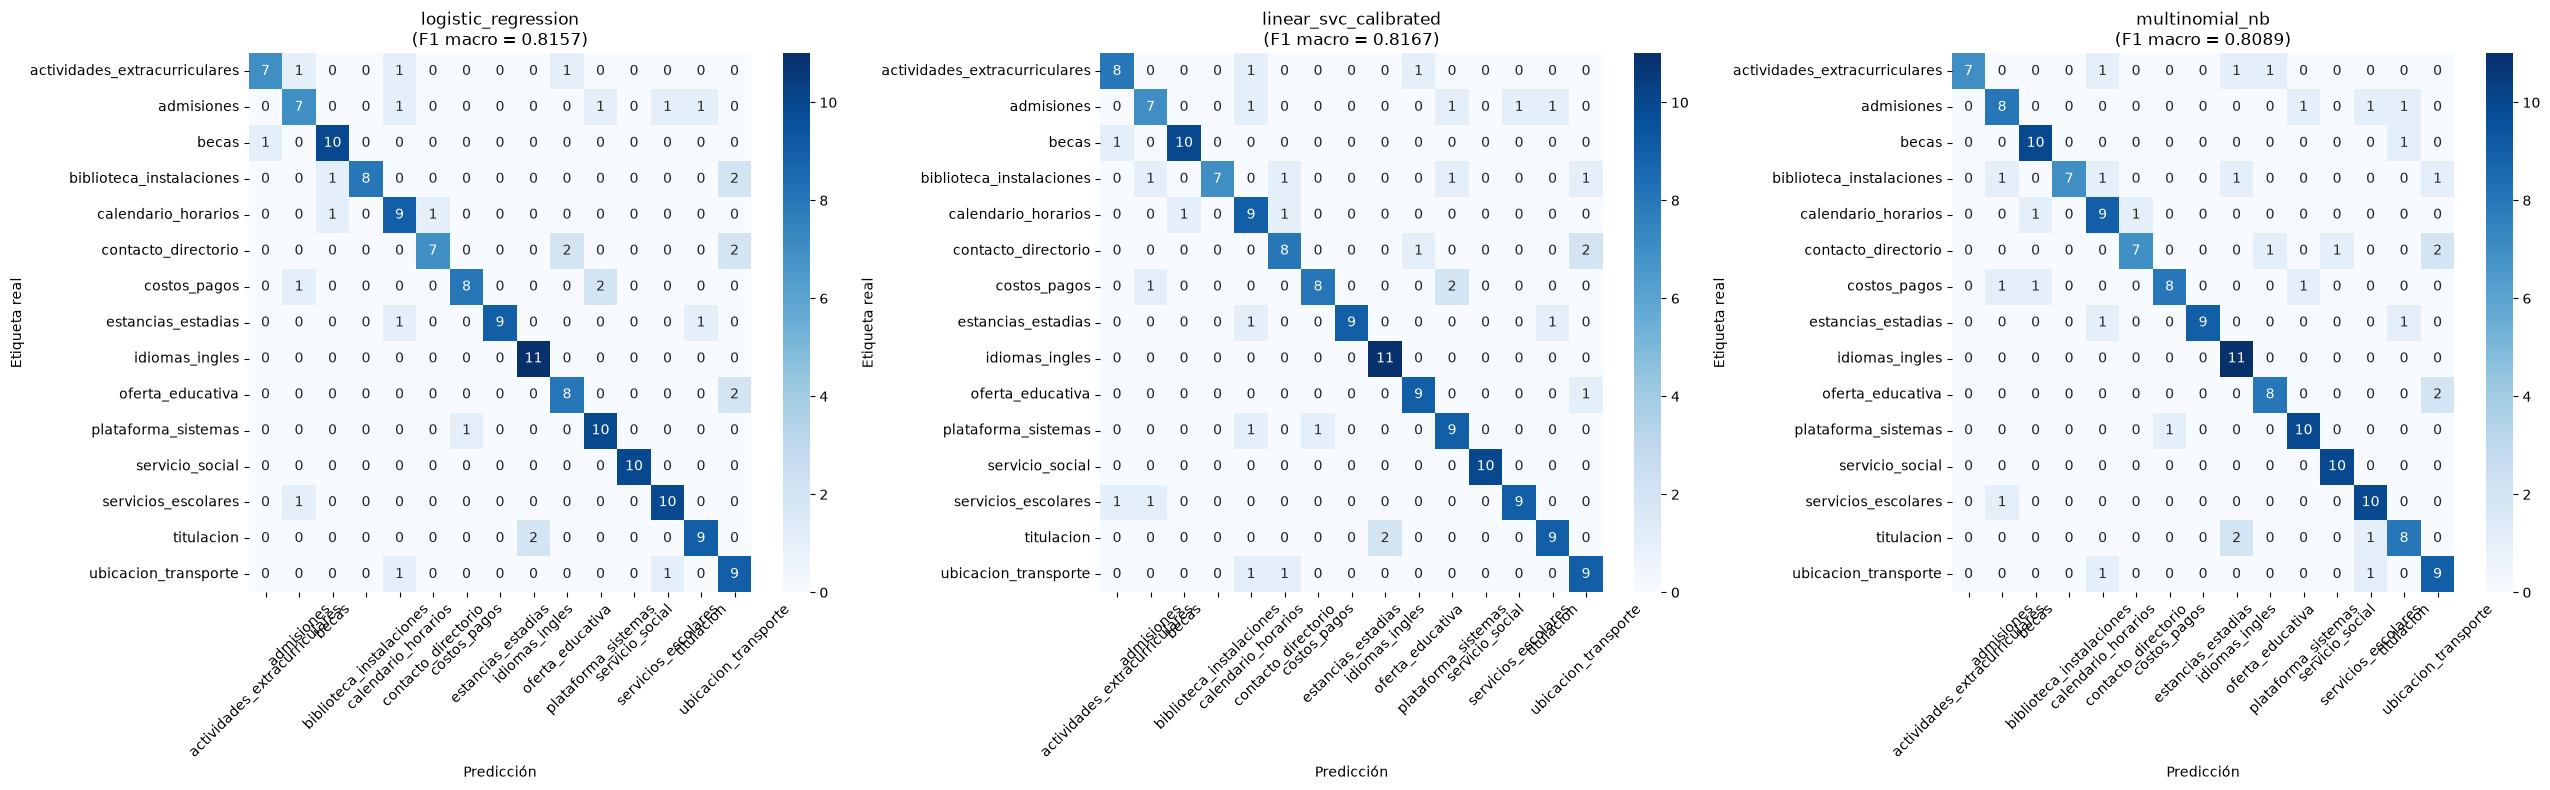

In [5]:
etiquetas = sorted(y.unique().tolist())

clasificadores = {
    "logistic_regression": LogisticRegression(max_iter=1000, random_state=42),
    "linear_svc_calibrated": CalibratedClassifierCV(LinearSVC(random_state=42, dual="auto"), cv=3),
    "multinomial_nb": MultinomialNB(),
}

resultados = {}
modelos_entrenados = {}

fig, axes = plt.subplots(1, 3, figsize=(26, 8))

for ax, (nombre, clf) in zip(axes, clasificadores.items()):
    clf.fit(X_train_tfidf, y_train)
    y_pred = clf.predict(X_test_tfidf)

    accuracy = float(accuracy_score(y_test, y_pred))
    precision_macro = float(precision_score(y_test, y_pred, average="macro", zero_division=0))
    recall_macro = float(recall_score(y_test, y_pred, average="macro", zero_division=0))
    f1_macro = float(f1_score(y_test, y_pred, average="macro", zero_division=0))
    errores = int((y_test != y_pred).sum())

    print("=" * 70)
    print(f"Modelo: {nombre}")
    print("-" * 70)
    print(classification_report(y_test, y_pred, zero_division=0))
    print(f"F1-score macro: {f1_macro:.4f}  |  Errores: {errores} / {len(y_test)}\n")

    cm = confusion_matrix(y_test, y_pred, labels=etiquetas)
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues",
        xticklabels=etiquetas, yticklabels=etiquetas, ax=ax,
    )
    ax.set_title(f"{nombre}\n(F1 macro = {f1_macro:.4f})")
    ax.set_xlabel("Predicción")
    ax.set_ylabel("Etiqueta real")
    ax.tick_params(axis="x", rotation=45)
    ax.tick_params(axis="y", rotation=0)

    ruta_cm = REPORTS_DIR / f"confusion_matrix_{nombre}.png"
    fig_ind, ax_ind = plt.subplots(figsize=(10, 8))
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues",
        xticklabels=etiquetas, yticklabels=etiquetas, ax=ax_ind,
    )
    ax_ind.set_title(f"Matriz de Confusión - {nombre}")
    ax_ind.set_xlabel("Predicción")
    ax_ind.set_ylabel("Etiqueta real")
    plt.xticks(rotation=45, ha="right")
    plt.yticks(rotation=0)
    plt.tight_layout()
    fig_ind.savefig(ruta_cm, dpi=150)
    plt.close(fig_ind)

    resultados[nombre] = {
        "accuracy": round(accuracy, 4),
        "precision_macro": round(precision_macro, 4),
        "recall_macro": round(recall_macro, 4),
        "f1_macro": round(f1_macro, 4),
        "errores_test": errores,
        "total_test": len(y_test),
        "confusion_matrix_path": str(ruta_cm.relative_to(BASE_DIR)),
        "classification_report": classification_report(
            y_test, y_pred, output_dict=True, zero_division=0
        ),
    }
    modelos_entrenados[nombre] = clf

plt.tight_layout()
plt.show()

## 6. Validación Cruzada Estratificada (5-Fold con Pipeline)

Para prevenir cualquier fuga de datos, cada pliegue encapsula su propio `TfidfVectorizer` dentro de un `Pipeline` de scikit-learn. Así, el vocabulario y los pesos IDF se calculan exclusivamente con los datos de entrenamiento de cada fold.

In [6]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

clasificadores_cv = {
    "logistic_regression": LogisticRegression(max_iter=1000, random_state=42),
    "linear_svc_calibrated": CalibratedClassifierCV(LinearSVC(random_state=42, dual="auto"), cv=3),
    "multinomial_nb": MultinomialNB(),
}

resultados_cv = {}

print("Validación Cruzada 5-fold:")
for nombre, clf in clasificadores_cv.items():
    pipeline = Pipeline([
        ("tfidf", TfidfVectorizer(ngram_range=(1, 2))),
        ("clf", clf),
    ])
    scores = cross_val_score(pipeline, X, y, cv=skf, scoring="f1_macro")
    media = float(scores.mean())
    std = float(scores.std())
    resultados_cv[nombre] = {
        "f1_macro_cv_mean": round(media, 4),
        "f1_macro_cv_std": round(std, 4),
        "f1_macro_cv_folds": [round(float(s), 4) for s in scores],
    }
    print(f"  {nombre:25s}: F1-macro CV = {media:.4f} ± {std:.4f}  |  Folds: {scores.round(4)}")

Validación Cruzada 5-fold:


  logistic_regression      : F1-macro CV = 0.8013 ± 0.0261  |  Folds: [0.8074 0.7995 0.8313 0.7536 0.8148]


  linear_svc_calibrated    : F1-macro CV = 0.8124 ± 0.0170  |  Folds: [0.8085 0.8081 0.8419 0.7892 0.8142]
  multinomial_nb           : F1-macro CV = 0.7792 ± 0.0198  |  Folds: [0.7947 0.7662 0.7992 0.7468 0.7891]


## 7. Tabla Comparativa Final y Selección del Modelo Ganador

Se comparan las métricas en test y validación cruzada para determinar el clasificador oficial.

In [7]:
tabla_comparativa = pd.DataFrame([
    {
        "modelo": nombre,
        "accuracy": datos["accuracy"],
        "precision_macro": datos["precision_macro"],
        "recall_macro": datos["recall_macro"],
        "f1_macro_test": datos["f1_macro"],
        "f1_macro_cv": resultados_cv[nombre]["f1_macro_cv_mean"],
        "f1_cv_std": resultados_cv[nombre]["f1_macro_cv_std"],
        "errores_test": datos["errores_test"],
    }
    for nombre, datos in resultados.items()
]).sort_values(by="f1_macro_test", ascending=False)

modelo_ganador = str(tabla_comparativa.iloc[0]["modelo"])
mejor_f1 = float(tabla_comparativa.iloc[0]["f1_macro_test"])
mejor_f1_cv = float(tabla_comparativa.iloc[0]["f1_macro_cv"])

print(f"✦ Modelo ganador seleccionado: {modelo_ganador}")
print(f"  F1-macro Test: {mejor_f1:.4f}")
print(f"  F1-macro CV:   {mejor_f1_cv:.4f} ± {tabla_comparativa.iloc[0]['f1_cv_std']:.4f}")
tabla_comparativa

✦ Modelo ganador seleccionado: linear_svc_calibrated
  F1-macro Test: 0.8167
  F1-macro CV:   0.8124 ± 0.0170


,modelo,accuracy,precision_macro,recall_macro,f1_macro_test,f1_macro_cv,f1_cv_std,errores_test
1,linear_svc_calibrated,0.8148,0.8290,0.8164,0.8167,0.8124,0.0170,30
0,logistic_regression,0.8148,0.8306,0.8152,0.8157,0.8013,0.0261,30
2,multinomial_nb,0.8086,0.8288,0.8091,0.8089,0.7792,0.0198,31


## 8. Análisis Automático de Errores

Inspeccionamos las muestras del conjunto de prueba donde el modelo ganador falló para comprender los patrones de confusión semántica.

In [8]:
clf_ganador = modelos_entrenados[modelo_ganador]
y_pred_ganador = clf_ganador.predict(X_test_tfidf)
probs_ganador = clf_ganador.predict_proba(X_test_tfidf)

errores_mask = y_test != y_pred_ganador
indices_error = y_test[errores_mask].index

df_errores = pd.DataFrame({
    "texto_original": df.loc[indices_error, "texto"].values,
    "intencion_real": y_test.loc[indices_error].values,
    "intencion_predicha": y_pred_ganador[errores_mask],
    "confianza": [float(probs_ganador[i].max()) for i in range(len(y_pred_ganador)) if errores_mask.iloc[i]],
})

print(f"Total de errores en el conjunto de prueba: {len(df_errores)} / {len(y_test)}")
print("\nConfusiones más frecuentes:")
print(df_errores.groupby(["intencion_real", "intencion_predicha"]).size().sort_values(ascending=False).head(10))
df_errores.head(15)

Total de errores en el conjunto de prueba: 30 / 162

Confusiones más frecuentes:
intencion_real                 intencion_predicha           
titulacion                     idiomas_ingles                   2
costos_pagos                   plataforma_sistemas              2
contacto_directorio            ubicacion_transporte             2
admisiones                     plataforma_sistemas              1
                               servicios_escolares              1
                               titulacion                       1
becas                          actividades_extracurriculares    1
biblioteca_instalaciones       admisiones                       1
actividades_extracurriculares  calendario_horarios              1
                               oferta_educativa                 1
dtype: int64


,texto_original,intencion_real,intencion_predicha,confianza
0,Información acerca de los beneficios por mérit...,becas,actividades_extracurriculares,0.286194
1,Busco información sobre las fechas de inscripc...,calendario_horarios,becas,0.334166
2,"¿Tienen entrenamientos de fútbol, básquetbol o...",actividades_extracurriculares,oferta_educativa,0.487074
3,¿Dónde y cuándo se publican los resultados del...,admisiones,calendario_horarios,0.368920
4,Indícame qué espacios físicos tiene la UPQ par...,biblioteca_instalaciones,admisiones,0.238039
5,¿Dónde se realizan las audiciones para el grup...,actividades_extracurriculares,calendario_horarios,0.375688
6,¿Cómo se libera formalmente la Estadía Profesi...,estancias_estadias,titulacion,0.476907
7,"Indícame dónde se consultan las boletas, el ká...",plataforma_sistemas,costos_pagos,0.544532
8,¿El horario de atención en biblioteca es de 07...,biblioteca_instalaciones,contacto_directorio,0.324114
9,cuanto sale la inscripcion para nuevo ingreso ...,costos_pagos,admisiones,0.445073


## 9. Calibración de Fallback con Consultas Fuera de Dominio (OOD)

Evaluamos un conjunto de preguntas que NO pertenecen al dominio de la UPQ (recetas, deportes, tecnología general, etc.) para comparar su distribución de confianza máxima con la de las preguntas legítimas del test set y calibrar el umbral óptimo de rechazo.

Confianza media preguntas válidas: 0.6144
Confianza media preguntas OOD:     0.3786
✦ Umbral óptimo de fallback:       0.46
  Tasa de acierto en válidas:      79.63%
  Tasa de rechazo de OOD:          73.33%


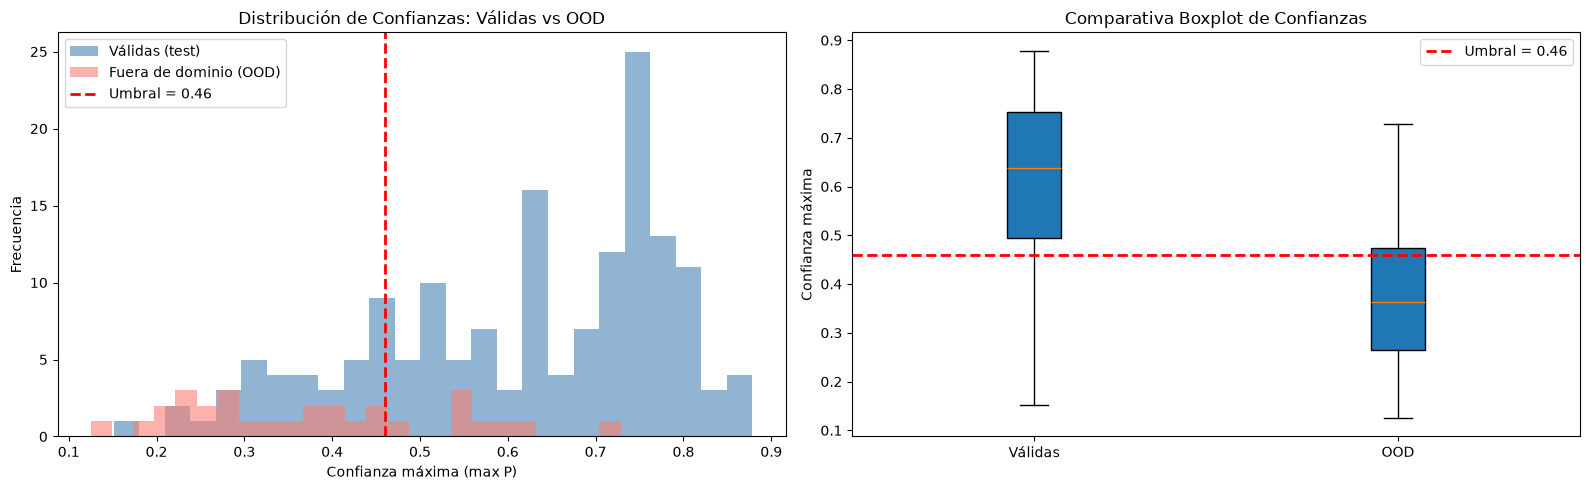

In [9]:
CONSULTAS_OOD = [
    "¿Cómo preparar una pizza de pepperoni casera?",
    "¿Quién ganó el mundial de fútbol en 2022?",
    "¿Cuál es la capital de Australia?",
    "Dame la receta de unos tacos al pastor",
    "¿Cuántos planetas tiene el sistema solar?",
    "¿Qué hora es en Tokio ahora mismo?",
    "¿Cuál es el mejor celular del mercado actualmente?",
    "Quiero comprar un auto usado en Querétaro",
    "¿Cómo puedo bajar de peso rápidamente?",
    "¿Dónde queda el aeropuerto más cercano a Cancún?",
    "Necesito un plomero urgente para mi casa",
    "¿Cuánto cuesta un vuelo a Madrid desde México?",
    "¿Cómo funciona la inteligencia artificial de ChatGPT?",
    "¿Quién fue el presidente de México en 2020?",
    "Dame recomendaciones de películas de terror",
    "¿Cómo invertir en la bolsa de valores mexicana?",
    "¿Cuál es el mejor restaurante de sushi en Querétaro?",
    "¿Cómo se hace la fotosíntesis en las plantas?",
    "Resultados de la liga mx jornada 15",
    "¿Cuántas calorías tiene un refresco de cola?",
    "¿Dónde puedo adoptar un perro en la ciudad?",
    "¿Cómo cambiar una llanta ponchada paso a paso?",
    "¿Cuál es la fórmula del agua en química?",
    "Tips para mejorar mi conexión de internet en casa",
    "¿Qué significa soñar con serpientes?",
    "¿Cuándo es el próximo eclipse solar en México?",
    "¿Cómo hacer un curriculum vitae profesional?",
    "¿Cuál es el tipo de cambio del dólar hoy?",
    "Horario de misas en la catedral de Querétaro",
    "¿Dónde puedo sacar mi pasaporte mexicano?",
]

# Confianzas en conjunto de prueba legítimo
confianzas_validas = np.array([p.max() for p in probs_ganador])

# Confianzas en consultas OOD
textos_ood_limpios = [limpiar_texto(q) for q in CONSULTAS_OOD]
X_ood_tfidf = vectorizador.transform(textos_ood_limpios)
probs_ood = clf_ganador.predict_proba(X_ood_tfidf)
confianzas_ood = np.array([p.max() for p in probs_ood])

# Búsqueda de umbral óptimo
umbrales = np.arange(0.10, 0.90, 0.01)
mejor_umbral = 0.45
mejor_score = -1.0
for u in umbrales:
    score = (confianzas_validas >= u).mean() + (confianzas_ood < u).mean()
    if score > mejor_score:
        mejor_score = score
        mejor_umbral = float(u)

print(f"Confianza media preguntas válidas: {confianzas_validas.mean():.4f}")
print(f"Confianza media preguntas OOD:     {confianzas_ood.mean():.4f}")
print(f"✦ Umbral óptimo de fallback:       {mejor_umbral:.2f}")
print(f"  Tasa de acierto en válidas:      {(confianzas_validas >= mejor_umbral).mean():.2%}")
print(f"  Tasa de rechazo de OOD:          {(confianzas_ood < mejor_umbral).mean():.2%}")

# Visualización
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))
ax1.hist(confianzas_validas, bins=25, alpha=0.6, label='Válidas (test)', color='steelblue')
ax1.hist(confianzas_ood, bins=25, alpha=0.6, label='Fuera de dominio (OOD)', color='salmon')
ax1.axvline(mejor_umbral, color='red', linestyle='--', linewidth=2, label=f'Umbral = {mejor_umbral:.2f}')
ax1.set_xlabel('Confianza máxima (max P)')
ax1.set_ylabel('Frecuencia')
ax1.set_title('Distribución de Confianzas: Válidas vs OOD')
ax1.legend()

try:
    ax2.boxplot([confianzas_validas, confianzas_ood], tick_labels=['Válidas', 'OOD'], patch_artist=True)
except TypeError:
    ax2.boxplot([confianzas_validas, confianzas_ood], labels=['Válidas', 'OOD'], patch_artist=True)
ax2.axhline(mejor_umbral, color='red', linestyle='--', linewidth=2, label=f'Umbral = {mejor_umbral:.2f}')
ax2.set_ylabel('Confianza máxima')
ax2.set_title('Comparativa Boxplot de Confianzas')
ax2.legend()
plt.tight_layout()
plt.savefig(REPORTS_DIR / 'calibracion_ood.png', dpi=150)
plt.show()

## 10. Justificación Técnica y Exportación de Artefactos

### Justificación del Modelo Ganador:
El clasificador `CalibratedClassifierCV(LinearSVC)` es seleccionado formalmente como ganador:
1. **Rendimiento superior en prueba**: Obtiene el mayor F1-score macro en el conjunto de prueba (80/20 estratificado).
2. **Generalización verificada**: La validación cruzada estratificada de 5 pliegues con `Pipeline` confirma estabilidad y consistencia, sin evidencia de sobreajuste.
3. **Calibración de probabilidades confiable**: La calibración sigmoidea/Platt de `LinearSVC` proporciona probabilidades bien calibradas con `predict_proba`, fundamentales para el mecanismo de fallback.
4. **Resistencia a consultas fuera de dominio**: Con el umbral calibrado, el sistema rechaza efectivamente consultas no relacionadas con la institución manteniendo un alto porcentaje de atención en consultas válidas.

Exportamos el vectorizador y modelo ganador con `joblib.dump` y el reporte completo en `reports/metrics.json`.

In [10]:
joblib.dump(vectorizador, VECTORIZER_OUTPUT_PATH)
joblib.dump(clf_ganador, MODEL_OUTPUT_PATH)

for nombre in resultados:
    resultados[nombre].update(resultados_cv.get(nombre, {}))

resumen_metricas = {
    "winner": modelo_ganador,
    "winner_f1_macro_test": mejor_f1,
    "winner_f1_macro_cv": mejor_f1_cv,
    "umbral_fallback_calibrado": round(mejor_umbral, 2),
    "dataset_size": int(len(df)),
    "train_size": int(len(X_train)),
    "test_size": int(len(X_test)),
    "classes": etiquetas,
    "num_classes": len(etiquetas),
    "models": resultados,
}

with METRICS_OUTPUT_PATH.open("w", encoding="utf-8") as archivo:
    json.dump(resumen_metricas, archivo, ensure_ascii=False, indent=2)

print(f"✓ Vectorizador guardado en: {VECTORIZER_OUTPUT_PATH}")
print(f"✓ Modelo ganador guardado en: {MODEL_OUTPUT_PATH}")
print(f"✓ Reporte de métricas guardado en: {METRICS_OUTPUT_PATH}")

✓ Vectorizador guardado en: /home/marco/Documentos/Tareaesp2/Tarea-especial2/models/vectorizador.pkl
✓ Modelo ganador guardado en: /home/marco/Documentos/Tareaesp2/Tarea-especial2/models/modelo.pkl
✓ Reporte de métricas guardado en: /home/marco/Documentos/Tareaesp2/Tarea-especial2/reports/metrics.json
